# ResNet-50 fine-tuning on four GPUs
Run all cells from VS Code connected to BigMac. Four independent experiments run concurrently, one on each GPU. Each uses the same pretrained model and trains its last block and final layer.

The small train_visa_resnet50.py script runs each experiment. Progress appears below the training cell and is saved in each GPU folder. If your laptop disconnects, reconnect, run setup and data/model definitions, then rerun the training cell to reconnect to the existing jobs. Interrupting the notebook's monitoring cell leaves the jobs running.

Change OUTPUT_DIR to a new folder for a new experiment. An existing folder reuses its saved jobs and results. Evaluation uses the first split's checkpoint for the learning rate with the best mean validation AP across both splits. The test results remain exploratory.


## 1. Imports and settings

In [1]:
import csv
import json
import os
import sys
import time
from itertools import product
import math
import shutil
from torch.utils.data import Subset
from sklearn.metrics import confusion_matrix
import subprocess
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet50_Weights, resnet50
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay,
)

SEED = 42
SPLIT_SEEDS = [42, 123]
GPU_INDEX = 0
BATCH_SIZE = 16
EPOCHS = 10
BACKBONE_RATES = [1e-5, 1e-4]
HEAD_RATE = 1e-3
VALIDATION_FRACTION = 0.2
TARGET_RECALL = 0.9
DATA_DIR = Path("visa_data")
OUTPUT_DIR = Path("results/full_visa_resnet50_parallel")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device(f"cuda:{GPU_INDEX}" if torch.cuda.is_available() else "cpu")
print("Evaluation device", device)
print("Training GPUs", torch.cuda.device_count())


Evaluation device cuda:0
Training GPUs 4


## 2. Load the data
Reuse the official VisA split and extract missing images if necessary.

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

def download(url, destination):
    if destination.is_file():
        return
    partial = destination.with_suffix(destination.suffix + ".part")
    subprocess.run([
        "curl", "--fail", "--location", "--retry", "2",
        "--output", str(partial), url,
    ], check=True)
    partial.replace(destination)

split_file = DATA_DIR / "2cls_highshot.csv"
download("https://raw.githubusercontent.com/amazon-science/spot-diff/main/split_csv/2cls_highshot.csv", split_file)
with split_file.open(newline="") as file:
    rows = list(csv.DictReader(file))
assert rows, "No images found for the selected product."

missing_images = {row["image"] for row in rows if not (DATA_DIR / row["image"]).is_file()}
if missing_images:
    archive = DATA_DIR / "VisA_20220922.tar"
    download("https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar", archive)
    with tarfile.open(archive) as tar:
        for member in tar:
            relative_path = Path(member.name)
            if str(relative_path) in missing_images and member.isfile():
                destination = (DATA_DIR / relative_path).resolve()
                assert DATA_DIR.resolve() in destination.parents
                destination.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as source, destination.open("wb") as target:
                    shutil.copyfileobj(source, target)
assert all((DATA_DIR / row["image"]).is_file() for row in rows), "Some images are missing."
table = pd.DataFrame(rows)
display(pd.crosstab([table["object"], table["split"]], table["label"]))


label             anomaly  normal
object     split                 
candle     test        40     400
           train       60     600
capsules   test        40     241
           train       60     361
cashew     test        40     200
           train       60     300
chewinggum test        40     201
           train       60     302
fryum      test        40     200
           train       60     300
macaroni1  test        40     400
           train       60     600
macaroni2  test        40     400
           train       60     600
pcb1       test        40     402
           train       60     602
pcb2       test        40     400
           train       60     601
pcb3       test        40     402
           train       60     604
pcb4       test        40     402
           train       60     603
pipe_fryum test        40     200
           train       60     300

## 3. Prepare images and the model
Freeze earlier layers and train layer4 plus the final layer. Keep batch normalization statistics fixed because batches are small.

In [3]:
weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

class VisaDataset(Dataset):
    def __init__(self, split):
        self.examples = [row for row in rows if row["split"] == split]

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        row = self.examples[index]
        with Image.open(DATA_DIR / row["image"]) as image:
            pixels = preprocess(image.convert("RGB"))
        label = torch.tensor({"normal": 0, "anomaly": 1}[row["label"]], dtype=torch.float32)
        return pixels, label

train_data = VisaDataset("train")
test_data = VisaDataset("test")
assert len(train_data) and len(test_data)
assert {r["image"] for r in train_data.examples}.isdisjoint(r["image"] for r in test_data.examples)

def build_model():
    torch.manual_seed(SEED)
    model = resnet50(weights=weights)
    model.requires_grad_(False)
    model.layer4.requires_grad_(True)
    model.fc = nn.Linear(model.fc.in_features, 1)
    return model.to(device)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    scores, targets = [], []
    for images, labels in loader:
        logits = model(images.to(device)).squeeze(1)
        scores.append(logits.sigmoid().cpu())
        targets.append(labels)
    return torch.cat(scores).numpy(), torch.cat(targets).numpy().astype(int)

def choose_threshold(labels, scores):
    defect_scores = sorted(scores[labels == 1], reverse=True)
    required = math.ceil(TARGET_RECALL * len(defect_scores))
    return float(defect_scores[required - 1])


## 4. Run four experiments and watch progress
Each GPU runs one learning-rate/split combination. Training settings are shown above. The script uses batch size 16, head learning rate 0.001, 20% validation, and a 90% validation recall target.


In [4]:
# Start each experiment once. Rerunning this cell reconnects to the saved jobs.
assert torch.cuda.device_count() >= 4, "This experiment needs four visible GPUs."
assert len(SPLIT_SEEDS) * len(BACKBONE_RATES) == 4
worker = Path("train_visa_resnet50.py").resolve()
manifest = OUTPUT_DIR / "jobs.json"
if manifest.exists():
    jobs = json.loads(manifest.read_text())
    assert all(job["epochs"] == EPOCHS for job in jobs), "Choose a new OUTPUT_DIR when changing settings."
    assert len(jobs) == 4, "Incomplete job list. Check progress logs before starting a new output folder."
    assert [(job["split"], job["rate"]) for job in jobs] == list(product(SPLIT_SEEDS, BACKBONE_RATES)), "Choose a new OUTPUT_DIR when changing settings."
    print("Reconnecting to saved jobs.")
else:
    jobs = []
    for gpu, (split_seed, rate) in enumerate(product(SPLIT_SEEDS, BACKBONE_RATES)):
        folder = (OUTPUT_DIR / f"gpu_{gpu}").resolve()
        folder.mkdir(parents=True, exist_ok=True)
        log_path = folder / "progress.log"
        command = [
            sys.executable, "-u", str(worker), "--gpu", str(gpu),
            "--split", str(split_seed), "--rate", str(rate), "--epochs", str(EPOCHS),
            "--data", str(DATA_DIR.resolve()), "--output", str(folder),
        ]
        with log_path.open("w") as log:
            process = subprocess.Popen(
                command, stdout=log, stderr=subprocess.STDOUT,
                stdin=subprocess.DEVNULL, start_new_session=True,
            )
        jobs.append({"gpu": gpu, "pid": process.pid, "folder": str(folder),
                     "epochs": EPOCHS, "split": split_seed, "rate": rate})
        manifest.write_text(json.dumps(jobs, indent=2))
    print("Started four experiments.")

# Show new log lines every five seconds. Logs remain available after disconnection.
positions = {job["gpu"]: 0 for job in jobs}
while True:
    finished = 0
    for job in jobs:
        folder = Path(job["folder"])
        lines = (folder / "progress.log").read_text().splitlines()
        for line in lines[positions[job["gpu"]]:]:
            print(f"GPU {job['gpu']} | {line}", flush=True)
        positions[job["gpu"]] = len(lines)
        if (folder / "finished.txt").exists():
            finished += 1
        else:
            process_file = Path(f"/proc/{job['pid']}/stat")
            assert process_file.exists(), f"GPU {job['gpu']} stopped. Check its progress.log."
            assert process_file.read_text().split()[2] != "Z", f"GPU {job['gpu']} failed. Check its progress.log."
    if finished == len(jobs):
        break
    time.sleep(5)

runs = pd.concat([pd.read_csv(Path(job["folder"]) / "validation_runs.csv") for job in jobs], ignore_index=True)
history = pd.concat([pd.read_csv(Path(job["folder"]) / "training_history.csv") for job in jobs], ignore_index=True)
display(runs.drop(columns="checkpoint"))
mean_ap = runs.groupby("backbone_rate")["validation_ap"].mean()
display(mean_ap.to_frame("Mean validation AP"))
best_rate = mean_ap.idxmax()
selected = runs[(runs["backbone_rate"] == best_rate) & (runs["split_seed"] == SPLIT_SEEDS[0])].iloc[0]
THRESHOLD = float(selected["threshold"])
model = build_model()
model.load_state_dict(torch.load(selected["checkpoint"], map_location=device, weights_only=True))
display(selected)
runs.to_csv(OUTPUT_DIR / "validation_runs.csv", index=False)
history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)


Started four experiments.
GPU 0 | GPU 0: split=42, learning rate=1e-05
GPU 1 | GPU 1: split=42, learning rate=0.0001
GPU 2 | GPU 2: split=123, learning rate=1e-05
GPU 3 | GPU 3: split=123, learning rate=0.0001
GPU 0 | split=42, lr=1e-05, epoch=1, validation AP=0.5511
GPU 1 | split=42, lr=0.0001, epoch=1, validation AP=0.4717
GPU 2 | split=123, lr=1e-05, epoch=1, validation AP=0.5170
GPU 3 | split=123, lr=0.0001, epoch=1, validation AP=0.4929
GPU 0 | split=42, lr=1e-05, epoch=2, validation AP=0.6676
GPU 1 | split=42, lr=0.0001, epoch=2, validation AP=0.6936
GPU 2 | split=123, lr=1e-05, epoch=2, validation AP=0.6819
GPU 3 | split=123, lr=0.0001, epoch=2, validation AP=0.8046
GPU 0 | split=42, lr=1e-05, epoch=3, validation AP=0.7250
GPU 2 | split=123, lr=1e-05, epoch=3, validation AP=0.7360
GPU 3 | split=123, lr=0.0001, epoch=3, validation AP=0.8204
GPU 1 | split=42, lr=0.0001, epoch=3, validation AP=0.8015
GPU 0 | split=42, lr=1e-05, epoch=4, validation AP=0.7692
GPU 2 | split=123, lr=1e

,split_seed,backbone_rate,best_epoch,validation_ap,threshold,recall,false_alarms,missed_defects
0,42,0.00001,9,0.808291,0.000594,0.902778,188,14
1,42,0.00010,10,0.875077,0.002778,0.902778,184,14
2,123,0.00001,10,0.794409,0.000030,0.902778,291,14
3,123,0.00010,8,0.925078,0.042609,0.902778,36,14


,Mean validation AP
backbone_rate,
0.00001,0.801350
0.00010,0.900077


split_seed                                                       42
backbone_rate                                                0.0001
best_epoch                                                       10
validation_ap                                              0.875077
threshold                                                  0.002778
recall                                                     0.902778
false_alarms                                                    184
missed_defects                                                   14
checkpoint        /home/russ/defect-detection-active-learning/re...
Name: 1, dtype: object

## 5. Evaluate the selected model
Use the shared threshold selected on the first validation split. Compare test misses and false alarms with the previous baseline of 46 misses and 783 false alarms.

,accuracy,average_precision,roc_auc,precision,recall,f1
ResNet-50,0.8304,0.8649,0.948,0.3841,0.8771,0.5343


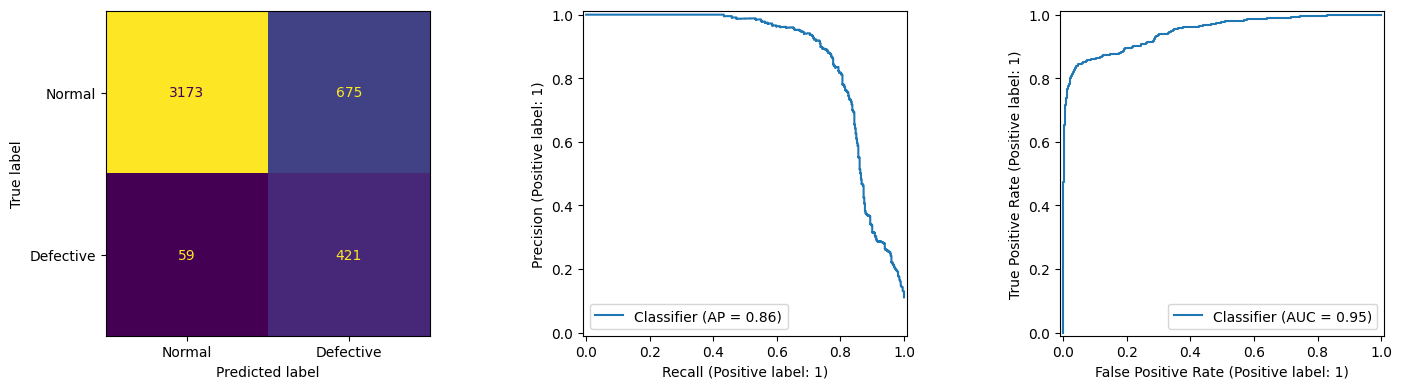

Missed defects 59


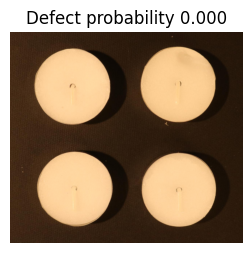

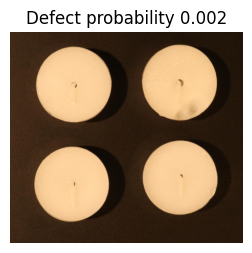

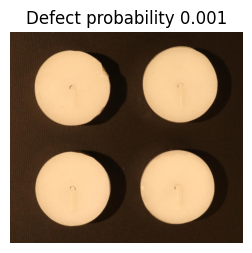

False alarms 675


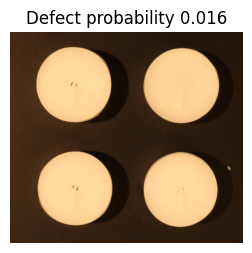

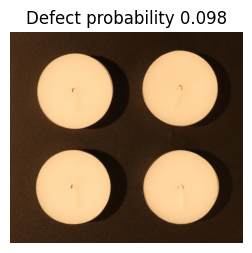

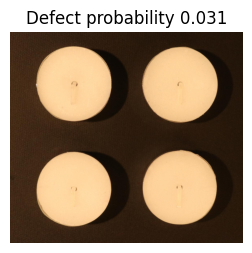

In [5]:
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
probabilities, actual = predict(model, test_loader)
predicted = (probabilities >= THRESHOLD).astype(int)
assert len(set(actual)) == 2, "Both classes are needed for ROC AUC."
metrics = {
    "accuracy": accuracy_score(actual, predicted),
    "average_precision": average_precision_score(actual, probabilities),
    "roc_auc": roc_auc_score(actual, probabilities),
    "precision": precision_score(actual, predicted, zero_division=0),
    "recall": recall_score(actual, predicted, zero_division=0),
    "f1": f1_score(actual, predicted, zero_division=0),
}
display(pd.DataFrame([metrics], index=["ResNet-50"]).round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=[0, 1], display_labels=["Normal", "Defective"], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(actual, probabilities, ax=axes[1])
RocCurveDisplay.from_predictions(actual, probabilities, ax=axes[2])
plt.tight_layout()
plt.show()

predictions = pd.DataFrame({
    "image": [row["image"] for row in test_data.examples],
    "product": [row["object"] for row in test_data.examples],
    "label": actual, "probability": probabilities, "prediction": predicted,
})
for title, mistakes in [
    ("Missed defects", predictions[(predictions["label"] == 1) & (predictions["prediction"] == 0)]),
    ("False alarms", predictions[(predictions["label"] == 0) & (predictions["prediction"] == 1)]),
]:
    print(title, len(mistakes))
    for row in mistakes.head(3).itertuples():
        with Image.open(DATA_DIR / row.image) as image:
            plt.figure(figsize=(3, 3))
            plt.imshow(image)
            plt.title(f"Defect probability {row.probability:.3f}")
            plt.axis("off")
            plt.show()


## 6. Save results by product
These files use the new fine-tuning results folder.

In [6]:
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
selected.to_frame("value").to_csv(OUTPUT_DIR / "selected_run.csv")
product_rows = []
for product_name, group in predictions.groupby("product"):
    tn, fp, fn, tp = confusion_matrix(group["label"], group["prediction"], labels=[0, 1]).ravel()
    product_rows.append({
        "product": product_name, "images": len(group),
        "detected_defects": tp, "missed_defects": fn, "false_alarms": fp,
        "accuracy": accuracy_score(group["label"], group["prediction"]),
        "recall": recall_score(group["label"], group["prediction"], zero_division=0),
        "precision": precision_score(group["label"], group["prediction"], zero_division=0),
        "average_precision": average_precision_score(group["label"], group["probability"]),
        "roc_auc": roc_auc_score(group["label"], group["probability"]),
    })
product_metrics = pd.DataFrame(product_rows)
display(product_metrics.round(4))
product_metrics.to_csv(OUTPUT_DIR / "per_product_metrics.csv", index=False)
print("Saved results to", OUTPUT_DIR.resolve())


,product,images,detected_defects,missed_defects,false_alarms,accuracy,recall,precision,average_precision,roc_auc
0,candle,440,34,6,4,0.9773,0.850,0.8947,0.9531,0.9932
1,capsules,281,26,14,30,0.8434,0.650,0.4643,0.6503,0.8949
2,cashew,240,40,0,35,0.8542,1.000,0.5333,0.9780,0.9945
3,chewinggum,241,37,3,5,0.9668,0.925,0.8810,0.9643,0.9826
4,fryum,240,37,3,6,0.9625,0.925,0.8605,0.9740,0.9929
5,macaroni1,440,38,2,228,0.4773,0.950,0.1429,0.7843,0.9154
6,macaroni2,440,30,10,52,0.8591,0.750,0.3659,0.6488,0.9044
7,pcb1,442,38,2,9,0.9751,0.950,0.8085,0.9710,0.9961
8,pcb2,440,39,1,275,0.3727,0.975,0.1242,0.8628,0.9535
9,pcb3,442,31,9,27,0.9186,0.775,0.5345,0.8227,0.9489


Saved results to /home/russ/defect-detection-active-learning/results/full_visa_resnet50_parallel
